In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
source_dir = Path(
    "/home/csb/Saloni/EMT_ID/EMT_ID/Figure_panc_differentiation/source_data"
)

cluster = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP",
    "Pre-endocrine",
    "Epsilon",
    "Delta",
    "Beta",
    "Alpha",
]

In [ ]:
id_long = pd.read_csv(
    source_dir / "Panc_endo_PRX_ID_scores.csv"
)

pairwise_matrix = pd.read_csv(
    source_dir / "Panc_endo_PRX_ID_pairwise_fdr.csv",
    index_col=0,
)

id_long["ID"] = pd.to_numeric(id_long["ID"], errors="coerce")

id_groups = {
    name: id_long.loc[
        id_long["clusters"] == name,
        "ID",
    ].dropna().to_numpy()
    for name in cluster
}

id_mean = {
    name: np.mean(values)
    for name, values in id_groups.items()
}

id_sd = {
    name: np.std(values, ddof=1)
    for name, values in id_groups.items()
}

cell_counts = {
    name: len(values)
    for name, values in id_groups.items()
}

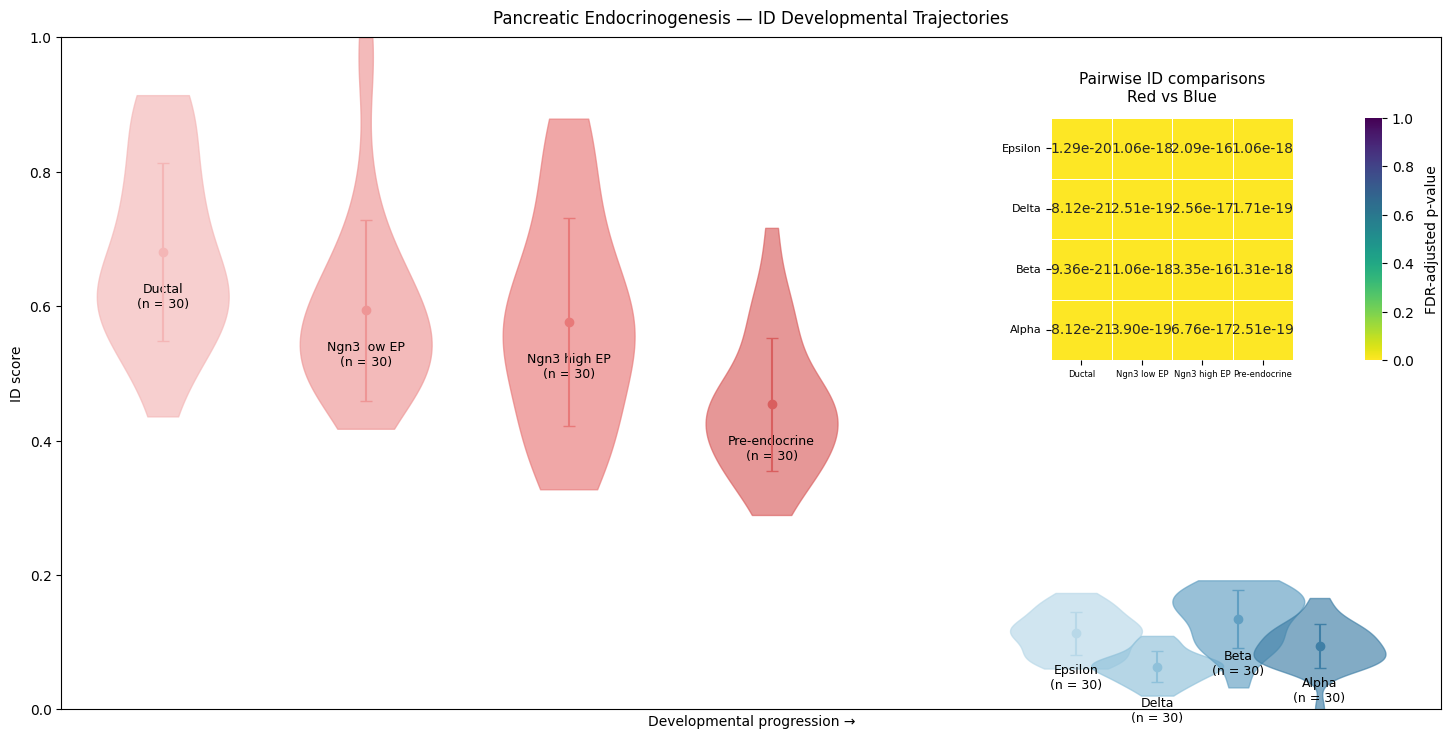

In [4]:
x = {
    "Ductal": 0.0,
    "Ngn3 low EP": 1.0,
    "Ngn3 high EP": 2.0,
    "Pre-endocrine": 3.0,
    "Epsilon": 4.5,
    "Delta": 4.9,
    "Beta": 5.3,
    "Alpha": 5.7,
}

colors = {
    "Ductal": "#F4B6B6",
    "Ngn3 low EP": "#EE9696",
    "Ngn3 high EP": "#E87979",
    "Pre-endocrine": "#D95F5F",
    "Epsilon": "#B8D8E8",
    "Delta": "#8FC1DA",
    "Beta": "#619FC2",
    "Alpha": "#3F7FA6",
}

fig, ax = plt.subplots(figsize=(15, 8))

for name in cluster:
    values = id_groups[name]

    violin = ax.violinplot(
        values,
        positions=[x[name]],
        widths=0.65,
        showmeans=False,
        showmedians=False,
        showextrema=False,
    )

    for body in violin["bodies"]:
        body.set_facecolor(colors[name])
        body.set_edgecolor(colors[name])
        body.set_alpha(0.65)

for name in cluster:
    ax.errorbar(
        x[name],
        id_mean[name],
        yerr=id_sd[name],
        fmt="o",
        color=colors[name],
        ecolor=colors[name],
        capsize=4,
        markersize=6,
        linewidth=1.5,
        zorder=5,
    )

for name in cluster:
    ax.text(
        x[name],
        id_mean[name] - 0.045,
        f"{name}\n(n = {cell_counts[name]})",
        ha="center",
        va="top",
        fontsize=9,
    )

ax.set_xlim(-0.5, 6.3)
ax.set_xticks([])
ax.set_xlabel("Developmental progression →")
ax.set_ylabel("ID score")
ax.set_ylim(0, 1)

ax.set_title(
    "Pancreatic Endocrinogenesis — ID Developmental Trajectories",
    pad=10,
)

red_group = [
    "Ductal",
    "Ngn3 low EP",
    "Ngn3 high EP",
    "Pre-endocrine",
]

blue_group = [
    "Epsilon",
    "Delta",
    "Beta",
    "Alpha",
]

pairwise_4x4 = pairwise_matrix.loc[
    blue_group,
    red_group,
].astype(float)

heatmap_ax = ax.inset_axes([0.67, 0.52, 0.27, 0.36])
cbar_ax = ax.inset_axes([0.945, 0.52, 0.012, 0.36])

sns.heatmap(
    pairwise_4x4,
    annot=True,
    fmt=".2e",
    cmap="viridis_r",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar=True,
    cbar_ax=cbar_ax,
    ax=heatmap_ax,
)

heatmap_ax.set_title(
    "Pairwise ID comparisons\nRed vs Blue",
    fontsize=11,
    pad=12,
)

heatmap_ax.set_xlabel("")
heatmap_ax.set_ylabel("")

heatmap_ax.tick_params(
    axis="x",
    rotation=0,
    labelsize=6,
)

heatmap_ax.tick_params(
    axis="y",
    rotation=0,
    labelsize=8,
)

cbar_ax.set_ylabel(
    "FDR-adjusted p-value",
    rotation=90,
    labelpad=8,
)

plt.subplots_adjust(
    left=0.05,
    right=0.97,
    top=0.92,
    bottom=0.08,
)

plt.show()